# 2-species reduced model with fraction QSS (all density-dependent)

This notebook studies a fraction-QSS reduction of `alldens_2sp_QSS.ipynb` when both mating and infanticide are density dependent.

The sex ratio is approximated by the invariant manifold

$$
F_i=M_i=N_i/2,
$$

and the infanticidal male frequency is fixed in the reduced model:

$$
q_{N,i}=1-p_i,\qquad q_{I,i}=p_i.
$$

For species $i$, define female reproductive-state fractions by

$$
x_{0,i}=\frac{F_{f,i}}{F_i},\quad
x_{1N,i}=\frac{C_{1,N,i}}{F_i},\quad
x_{2N,i}=\frac{C_{2,N,i}}{F_i},\quad
x_{1I,i}=\frac{C_{1,I,i}}{F_i},\quad
x_{2I,i}=\frac{C_{2,I,i}}{F_i},
$$

with $x_{0,i}+x_{1N,i}+x_{2N,i}+x_{1I,i}+x_{2I,i}=1$. On the sex-ratio manifold, the density-dependent mating and reset rates per female are

$$
a_i(N_i)=\alpha_iN_i/2,\qquad
h_i(N_i,p_i)=\gamma_ip_iN_i/2,
$$

and

$$
r_{I,i}=(1-s_i)r_{N,i},\qquad
b_i=\beta_i\left(r_{N,i}x_{2N,i}+r_{I,i}x_{2I,i}\right).
$$

The fraction-QSS equations are

$$
\begin{aligned}
\dot{x}_{0,i} &= -a_ix_{0,i}+(1+r_{N,i})\beta_ix_{2N,i}+(1+r_{I,i})\beta_ix_{2I,i}-b_ix_{0,i},\\
\dot{x}_{1N,i} &= a_i(1-p_i)x_{0,i}-(\beta_i+h_i+b_i)x_{1N,i},\\
\dot{x}_{2N,i} &= \beta_ix_{1N,i}-(\beta_i+h_i+b_i)x_{2N,i},\\
\dot{x}_{1I,i} &= a_ip_ix_{0,i}+h_i(x_{1N,i}+x_{2N,i}+x_{2I,i})-(\beta_i+b_i)x_{1I,i},\\
\dot{x}_{2I,i} &= \beta_ix_{1I,i}-(\beta_i+h_i+b_i)x_{2I,i}.
\end{aligned}
$$

The reduced density dynamics are

$$
\dot N_i=N_i\left[\beta_i\left(r_{N,i}x_{2N,i}^*+r_{I,i}x_{2I,i}^*\right)-d_i(N_i+\rho_{ij}N_j)\right].
$$


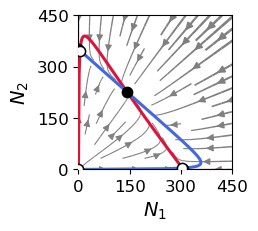

Equilibria:
[0. 0.] unstable
[  0.         351.43828906] stable
[  4.80526065 347.18395778] unstable
[142.81623303 225.45488537] stable
[303.71290344   3.92154922] unstable
[306.68023072   0.        ] stable


In [1]:
import numpy as np
from functools import lru_cache
import matplotlib.pyplot as plt
from scipy.optimize import brentq, root


# =========================
# Parameters
# =========================
params = {
    'alpha1': 1.0,
    'beta1': 1.0,
    'gamma1': 0.01,
    'd1': 0.001,
    'r_N1': 1.2,
    's1': 0.1,
    'p1': 0.8,

    'alpha2': 1.0,
    'beta2': 1.0,
    'gamma2': 0.01,
    'd2': 0.001,
    'r_N2': 1.0,
    's2': 0.1,
    'p2': 0.2,

    'rho12': 1.0,
    'rho21': 1.0,
}

plot_config = {
    'N1_min': 0.0,
    'N1_max': 450.0,
    'N2_min': 0.0,
    'N2_max': 450.0,
    'auto_margin': 3.5,
    'fallback_max': 500.0,
    'eps': 1e-6,
}


def r_I_from_cost(r_N, s):
    return (1.0 - s) * r_N


def _qss_fractions_from_birth_rate(mating_rate, beta, h, p_self, birth_rate):
    q_N = 1.0 - p_self
    q_I = p_self
    A = beta + h + birth_rate

    if A <= 0.0:
        return np.array([1.0, 0.0, 0.0, 0.0, 0.0], dtype=float)

    x1N_per_x0 = mating_rate * q_N / A
    x2N_per_x0 = beta * x1N_per_x0 / A

    denom_I = (beta + birth_rate) * (beta + birth_rate) / A + h * birth_rate / A
    numer_I_per_x0 = mating_rate * q_I + h * (x1N_per_x0 + x2N_per_x0)
    x1I_per_x0 = numer_I_per_x0 / denom_I
    x2I_per_x0 = beta * x1I_per_x0 / A

    total_per_x0 = 1.0 + x1N_per_x0 + x2N_per_x0 + x1I_per_x0 + x2I_per_x0
    x0 = 1.0 / total_per_x0
    return np.array(
        [
            x0,
            x0 * x1N_per_x0,
            x0 * x2N_per_x0,
            x0 * x1I_per_x0,
            x0 * x2I_per_x0,
        ],
        dtype=float,
    )


@lru_cache(maxsize=32768)
def _qss_fractions_scalar(N, alpha, beta, gamma, r_N, s, p_self):
    """QSS fractions [x0, x1N, x2N, x1I, x2I] for one species.

    For a fixed candidate birth rate b, the QSS equations are linear in the
    fractions. The only nonlinear condition is b = beta*(r_N*x2N + r_I*x2I),
    so a scalar brent solve is enough.
    """
    N = max(float(N), 0.0)
    values = np.asarray([alpha, beta, gamma, r_N, s, p_self], dtype=float)
    if not np.all(np.isfinite(values)) or alpha < 0 or beta <= 0 or gamma < 0 or r_N < 0 or not 0 <= s <= 1 or not 0 <= p_self <= 1:
        raise ValueError('Require finite alpha, gamma, r_N >= 0, beta > 0, and s, p in [0, 1].')
    r_I = r_I_from_cost(r_N, s)
    mating_rate = 0.5 * alpha * N
    h = 0.5 * gamma * p_self * N
    upper = max(beta * max(r_N, r_I), np.finfo(float).eps)

    def implied_birth_rate(candidate_birth_rate):
        x0, x1N, x2N, x1I, x2I = _qss_fractions_from_birth_rate(
            mating_rate, beta, h, p_self, candidate_birth_rate
        )
        return beta * (r_N * x2N + r_I * x2I)

    def residual(candidate_birth_rate):
        return implied_birth_rate(candidate_birth_rate) - candidate_birth_rate

    f0 = residual(0.0)
    f_upper = residual(upper)
    if abs(f0) <= 1e-14:
        birth_rate = 0.0
    elif abs(f_upper) <= 1e-14:
        birth_rate = upper
    elif f0 * f_upper < 0.0:
        birth_rate = float(brentq(residual, 0.0, upper, xtol=1e-12, rtol=1e-12, maxiter=100))
    else:
        raise RuntimeError('QSS birth-rate root is not bracketed.')

    fractions = _qss_fractions_from_birth_rate(mating_rate, beta, h, p_self, birth_rate)
    fractions[fractions < 0.0] = 0.0
    total = float(np.sum(fractions))
    if total > 0.0:
        fractions /= total
    return tuple(fractions)


def qss_fractions(N, alpha, beta, gamma, r_N, s, p_self):
    """Solve once per distinct density, including on mesh grids."""
    N_arr = np.asarray(N, dtype=float)
    if not np.all(np.isfinite(N_arr)):
        raise ValueError('Densities must be finite.')
    if N_arr.ndim == 0:
        return np.asarray(_qss_fractions_scalar(float(N_arr), alpha, beta, gamma, r_N, s, p_self))
    values, inverse = np.unique(N_arr, return_inverse=True)
    fractions = np.array([
        _qss_fractions_scalar(float(value), alpha, beta, gamma, r_N, s, p_self)
        for value in values
    ]).reshape((-1, 5))
    return np.moveaxis(fractions[inverse].reshape(N_arr.shape + (5,)), -1, 0)


def qss_birth_rate(N, alpha, beta, gamma, r_N, s, p_self):
    x0, x1N, x2N, x1I, x2I = qss_fractions(N, alpha, beta, gamma, r_N, s, p_self)
    r_I = r_I_from_cost(r_N, s)
    return beta * (r_N * x2N + r_I * x2I)


def species_H(alpha, beta, gamma, d, r_N, s, p_self, rho, N_self, N_other):
    birth_rate = qss_birth_rate(N_self, alpha, beta, gamma, r_N, s, p_self)
    comp = d * (N_self + rho * N_other)
    return birth_rate - comp


def H1(N1, N2, p):
    return species_H(
        p['alpha1'], p['beta1'], p['gamma1'], p['d1'],
        p['r_N1'], p['s1'], p['p1'], p['rho12'], N1, N2
    )


def H2(N1, N2, p):
    return species_H(
        p['alpha2'], p['beta2'], p['gamma2'], p['d2'],
        p['r_N2'], p['s2'], p['p2'], p['rho21'], N2, N1
    )


def dN1_dt(N1, N2, p):
    return N1 * H1(N1, N2, p)


def dN2_dt(N1, N2, p):
    return N2 * H2(N1, N2, p)


def reduced_rhs(time, y, p):
    N1, N2 = np.maximum(np.asarray(y, dtype=float), 0.0)
    return np.array([dN1_dt(N1, N2, p), dN2_dt(N1, N2, p)], dtype=float)


@lru_cache(maxsize=4096)
def single_species_equilibria(alpha, beta, gamma, d, r_N, s, p_self, n_scan=241):
    """Return all detected positive single-species density equilibria."""
    def f(N):
        return qss_birth_rate(N, alpha, beta, gamma, r_N, s, p_self) - d * N

    if d <= 0:
        raise ValueError('Density regulation d must be positive.')
    upper = beta * max(r_N, r_I_from_cost(r_N, s)) / d
    if upper <= 0:
        return ()
    # No positive equilibrium can exceed the maximum birth rate divided by d.
    grid = np.geomspace(max(np.finfo(float).tiny, upper * 1e-12), upper, int(n_scan))
    values = np.array([f(value) for value in grid], dtype=float)
    roots = []

    def register(value):
        value = float(value)
        if value <= 0.0 or not np.isfinite(value):
            return
        if not any(abs(value - existing) <= 1e-7 * max(1.0, value, existing) for existing in roots):
            roots.append(value)

    for left, right, f_left, f_right in zip(grid[:-1], grid[1:], values[:-1], values[1:]):
        if not (np.isfinite(f_left) and np.isfinite(f_right)):
            continue
        if f_left == 0.0:
            register(left)
        if f_left * f_right < 0.0:
            register(brentq(f, left, right, xtol=1e-11, rtol=1e-11, maxiter=200))
    if np.isfinite(values[-1]) and values[-1] == 0.0:
        register(grid[-1])
    roots.sort()
    return tuple(roots)


def single_species_equilibrium(alpha, beta, gamma, d, r_N, s, p_self):
    """Largest positive root, used for plot bounds and continuation seeds."""
    roots = single_species_equilibria(alpha, beta, gamma, d, r_N, s, p_self)
    return None if not roots else float(roots[-1])


def resolve_plot_limits(N1_single, N2_single, cfg):
    N1_auto = cfg['fallback_max'] if N1_single is None else cfg['auto_margin'] * N1_single
    N2_auto = cfg['fallback_max'] if N2_single is None else cfg['auto_margin'] * N2_single
    N1_max = N1_auto if cfg['N1_max'] is None else cfg['N1_max']
    N2_max = N2_auto if cfg['N2_max'] is None else cfg['N2_max']
    return cfg['N1_min'], float(N1_max), cfg['N2_min'], float(N2_max)


def numerical_jacobian(func, x, rel_step=1e-6, abs_step=1e-7):
    x = np.asarray(x, dtype=float)
    f0 = np.asarray(func(x), dtype=float)
    J = np.empty((f0.size, x.size), dtype=float)
    for k in range(x.size):
        h = max(abs_step, rel_step * max(1.0, abs(x[k])))
        xp = x.copy()
        xp[k] += h
        if x[k] <= h:
            J[:, k] = (np.asarray(func(xp), dtype=float) - f0) / h
        else:
            xm = x.copy()
            xm[k] -= h
            J[:, k] = (np.asarray(func(xp), dtype=float) - np.asarray(func(xm), dtype=float)) / (2.0 * h)
    return J


def jacobian(N1, N2, p):
    return numerical_jacobian(lambda z: reduced_rhs(0.0, z, p), np.array([N1, N2], dtype=float))


def origin_quadratic_coefficients(p):
    r_I1 = r_I_from_cost(p['r_N1'], p['s1'])
    r_I2 = r_I_from_cost(p['r_N2'], p['s2'])
    return np.array([
        0.5 * p['alpha1'] * ((1.0 - p['p1']) * p['r_N1'] + p['p1'] * r_I1) - p['d1'],
        0.5 * p['alpha2'] * ((1.0 - p['p2']) * p['r_N2'] + p['p2'] * r_I2) - p['d2'],
    ], dtype=float)


def classify_equilibrium(N1, N2, p, tol=1e-8):
    if abs(N1) <= tol and abs(N2) <= tol:
        quadratic_coefficients = origin_quadratic_coefficients(p)
        is_stable = bool(np.all(quadratic_coefficients < -tol))
        return is_stable, np.zeros(2, dtype=float)
    eigvals = np.linalg.eigvals(jacobian(N1, N2, p))
    return bool(np.max(np.real(eigvals)) < -tol), eigvals


def _append_unique_equilibrium(equilibria, point, p, tol=1e-6):
    point = np.maximum(np.asarray(point, dtype=float), 0.0)
    if any(np.linalg.norm(point - eq['point']) <= tol for eq in equilibria):
        return
    stable, eigvals = classify_equilibrium(point[0], point[1], p)
    equilibria.append({'point': point, 'stable': stable, 'eigenvalues': eigvals})


def find_equilibria(p, bounds):
    """Numerical search; isolated tangencies or very close roots may be missed."""
    N1_min, N1_max, N2_min, N2_max = bounds
    equilibria = []
    _append_unique_equilibrium(equilibria, [0.0, 0.0], p)

    N1_single_roots = single_species_equilibria(
        p['alpha1'], p['beta1'], p['gamma1'], p['d1'], p['r_N1'], p['s1'], p['p1']
    )
    N2_single_roots = single_species_equilibria(
        p['alpha2'], p['beta2'], p['gamma2'], p['d2'], p['r_N2'], p['s2'], p['p2']
    )
    for N1_single in N1_single_roots:
        if N1_min - 1e-8 <= N1_single <= N1_max + 1e-8:
            _append_unique_equilibrium(equilibria, [N1_single, 0.0], p)
    for N2_single in N2_single_roots:
        if N2_min - 1e-8 <= N2_single <= N2_max + 1e-8:
            _append_unique_equilibrium(equilibria, [0.0, N2_single], p)
    N1_single = None if not N1_single_roots else N1_single_roots[-1]
    N2_single = None if not N2_single_roots else N2_single_roots[-1]

    if p['rho12'] > 0:
        # H1 = 0 gives N2 explicitly. Solve H2 along each positive segment
        # of this nullcline instead of repeatedly solving a two-dimensional system.
        upper = min(N1_max, N1_single or 0.0)
        if upper > 0:
            edges = sorted(set([0.0, upper] + [v for v in N1_single_roots if v < upper]))
            for left, right in zip(edges[:-1], edges[1:]):
                midpoint = 0.5 * (left + right)
                if H1(midpoint, 0.0, p) <= 0:
                    continue

                def other_density(N1):
                    return H1(N1, 0.0, p) / (p['d1'] * p['rho12'])

                def residual(N1):
                    return H2(N1, max(0.0, other_density(N1)), p)

                grid = np.unique(np.concatenate([
                    np.linspace(left, right, 161),
                    left + np.geomspace((right - left) * 1e-10, right - left, 81),
                ]))
                values = np.array([residual(value) for value in grid])
                for a, b, fa, fb in zip(grid[:-1], grid[1:], values[:-1], values[1:]):
                    if fa * fb < 0 or fa == 0:
                        N1 = a if fa == 0 else brentq(residual, a, b, xtol=1e-10, rtol=1e-12)
                        N2 = other_density(N1)
                        if N1 > 1e-7 and N2 > 1e-7 and N1_min <= N1 <= N1_max and N2_min <= N2 <= N2_max:
                            _append_unique_equilibrium(equilibria, [N1, N2], p)
        equilibria.sort(key=lambda eq: tuple(eq['point']))
        return equilibria

    seeds = []
    for x in np.linspace(max(1e-6, N1_min), N1_max, 9):
        for y in np.linspace(max(1e-6, N2_min), N2_max, 9):
            seeds.append([x, y])
    if N1_single is not None and N2_single is not None:
        seeds.extend([
            [0.5 * N1_single, 0.5 * N2_single],
            [N1_single, N2_single],
            [0.25 * N1_single, N2_single],
            [N1_single, 0.25 * N2_single],
        ])

    def F(z):
        z = np.asarray(z, dtype=float)
        return np.array([H1(z[0], z[1], p), H2(z[0], z[1], p)], dtype=float)

    for seed in seeds:
        sol = root(F, np.asarray(seed, dtype=float), method='hybr')
        if not sol.success:
            continue
        point = np.asarray(sol.x, dtype=float)
        if not np.all(np.isfinite(point)) or np.any(point <= 1e-7):
            continue
        if not (N1_min - 1e-7 <= point[0] <= N1_max + 1e-7 and N2_min - 1e-7 <= point[1] <= N2_max + 1e-7):
            continue
        if np.linalg.norm(F(point), ord=np.inf) > 1e-7:
            continue
        _append_unique_equilibrium(equilibria, point, p)

    equilibria.sort(key=lambda eq: (eq['point'][0] <= 1e-8, eq['point'][1] <= 1e-8, eq['point'][0], eq['point'][1]))
    return equilibria

phase_plane_style = {
    'figsize': (2.0, 2.0),
    'n_grid': 220,
    'stream_density': 0.5,
    'stream_arrowsize': 1.0,
    'nullcline_lw': 2.2,
    'equilibrium_s': 54,
    'equal_aspect': True,
}

N1_single = single_species_equilibrium(params['alpha1'], params['beta1'], params['gamma1'], params['d1'], params['r_N1'], params['s1'], params['p1'])
N2_single = single_species_equilibrium(params['alpha2'], params['beta2'], params['gamma2'], params['d2'], params['r_N2'], params['s2'], params['p2'])
N1_min, N1_max, N2_min, N2_max = resolve_plot_limits(N1_single, N2_single, plot_config)

eps = plot_config['eps']
N1_vals = np.linspace(max(eps, N1_min), N1_max, phase_plane_style['n_grid'])
N2_vals = np.linspace(max(eps, N2_min), N2_max, phase_plane_style['n_grid'])
N1_grid, N2_grid = np.meshgrid(N1_vals, N2_vals)

H1_grid = H1(N1_grid, N2_grid, params)
H2_grid = H2(N1_grid, N2_grid, params)
U = N1_grid * H1_grid
V = N2_grid * H2_grid
speed = np.hypot(U, V)
equilibria = find_equilibria(params, (N1_min, N1_max, N2_min, N2_max))

line_width = 0.7 + 1.3 * speed / (np.nanmax(speed) + 1e-14)
fig, ax = plt.subplots(figsize=phase_plane_style['figsize'])
ax.streamplot(
    N1_vals, N2_vals, U, V,
    density=phase_plane_style['stream_density'],
    color='grey',
    linewidth=line_width,
    arrowsize=phase_plane_style['stream_arrowsize'],
    integration_direction='both',
    zorder=1,
)
ax.contour(N1_grid, N2_grid, H1_grid, levels=[0.0], colors=['crimson'], linewidths=phase_plane_style['nullcline_lw'], zorder=3)
ax.contour(N1_grid, N2_grid, H2_grid, levels=[0.0], colors=['royalblue'], linewidths=phase_plane_style['nullcline_lw'], zorder=3)

stable_points = np.array([eq['point'] for eq in equilibria if eq['stable']], dtype=float)
unstable_points = np.array([eq['point'] for eq in equilibria if not eq['stable']], dtype=float)
if stable_points.size:
    ax.scatter(stable_points[:, 0], stable_points[:, 1], s=phase_plane_style['equilibrium_s'], facecolors='black', edgecolors='black', linewidths=1.1, zorder=4)
if unstable_points.size:
    ax.scatter(unstable_points[:, 0], unstable_points[:, 1], s=phase_plane_style['equilibrium_s'], facecolors='white', edgecolors='black', linewidths=1.1, zorder=4)

ax.axhline(0.0, color='crimson', linestyle='--', linewidth=1.0, alpha=0.45, zorder=2)
ax.axvline(0.0, color='royalblue', linestyle='--', linewidth=1.0, alpha=0.45, zorder=2)
ax.set_xlim(N1_min, N1_max)
ax.set_ylim(N2_min, N2_max)
ax.set_xticks(np.arange(N1_min, N1_max + 1, 150))
ax.set_yticks(np.arange(N2_min, N2_max + 1, 150))
ax.set_xlabel(r'$N_1$', fontsize=14)
ax.set_ylabel(r'$N_2$', fontsize=14)
ax.tick_params(axis='both', labelsize=12)
if phase_plane_style['equal_aspect']:
    ax.set_aspect('equal', adjustable='box')

plt.show()

print('Equilibria:')
for eq in equilibria:
    print(eq['point'], 'stable' if eq['stable'] else 'unstable')


### Outcome diagram on the $p_1-p_2$ plane

In [4]:
from tqdm.auto import tqdm

p_plane_config = {
    'n_p1': 100,
    'n_p2': 100,
    'p1_min': 0.0,
    'p1_max': 1.0,
    'p2_min': 0.0,
    'p2_max': 1.0,
}

p1_values = np.linspace(p_plane_config['p1_min'], p_plane_config['p1_max'], p_plane_config['n_p1'])
p2_values = np.linspace(p_plane_config['p2_min'], p_plane_config['p2_max'], p_plane_config['n_p2'])

outcome_labels = [
    'coexistence',
    'boundary_bistability',
    'multistability',
    'unresolved',
    'both_extinct',
    'species1_extinct',
    'species2_extinct',
]
outcome_to_code = {label: idx for idx, label in enumerate(outcome_labels)}


def p_plane_bounds(p):
    """Use biological bounds, independently of phase-portrait display limits."""
    upper = []
    for i in (1, 2):
        if p[f'd{i}'] <= 0 or p[f'rho{12 if i == 1 else 21}'] < 0:
            raise ValueError('Require d > 0 and nonnegative competition coefficients.')
        birth_bound = p[f'beta{i}'] * max(p[f'r_N{i}'], r_I_from_cost(p[f'r_N{i}'], p[f's{i}']))
        upper.append(max(1.0, 1.01 * birth_bound / p[f'd{i}']))
    return 0.0, upper[0], 0.0, upper[1]


def classify_p_plane_outcome(equilibria, tol=1e-7):
    """Classify detected attractors; lack of an attractor is not extinction."""
    stable = [eq for eq in equilibria if eq['stable']]
    outcomes = set()
    for eq in stable:
        N1, N2 = eq['point']
        if N1 > tol and N2 > tol:
            outcomes.add('coexistence')
        elif N1 > tol:
            outcomes.add('species2_extinct')
        elif N2 > tol:
            outcomes.add('species1_extinct')
        else:
            outcomes.add('both_extinct')
    if not outcomes:
        return 'unresolved'
    if outcomes == {'species1_extinct', 'species2_extinct'}:
        return 'boundary_bistability'
    if len(outcomes) > 1:
        return 'multistability'
    return outcomes.pop()


outcome_grid = np.full((p2_values.size, p1_values.size), outcome_to_code['unresolved'], dtype=int)
total_grid_points = p1_values.size * p2_values.size

with tqdm(total=total_grid_points, desc='Scanning p1-p2 plane') as progress:
    for row, p2_value in enumerate(p2_values):
        for col, p1_value in enumerate(p1_values):
            p_scan = dict(params)
            p_scan['p1'] = float(p1_value)
            p_scan['p2'] = float(p2_value)
            bounds = p_plane_bounds(p_scan)
            scan_equilibria = find_equilibria(p_scan, bounds)
            outcome = classify_p_plane_outcome(scan_equilibria)
            outcome_grid[row, col] = outcome_to_code[outcome]
            progress.update(1)

Scanning p1-p2 plane:   0%|          | 0/10000 [00:00<?, ?it/s]

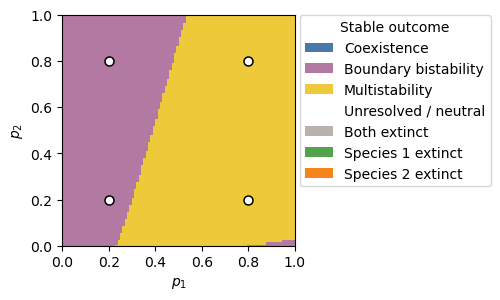

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

p_plane_plot_config = {
    'figure_size': (3.0, 3.0),
    'marker_points': [
        (0.2, 0.2),
        (0.2, 0.8),
        (0.8, 0.8),
        (0.8, 0.2),
    ],
    'marker_size': 42,
}

p_plane_colors = {
    'coexistence': '#4c78a8',
    'multistability': '#eeca3b',
    'unresolved': '#ffffff',
    'boundary_bistability': '#b279a2',
    'both_extinct': '#bab0ac',
    'species1_extinct': '#54a24b',
    'species2_extinct': '#f58518',
}

p_plane_display_labels = {
    'coexistence': 'Coexistence',
    'multistability': 'Multistability',
    'unresolved': 'Unresolved / neutral',
    'boundary_bistability': 'Boundary bistability',
    'both_extinct': 'Both extinct',
    'species1_extinct': 'Species 1 extinct',
    'species2_extinct': 'Species 2 extinct',
}

cmap = ListedColormap([p_plane_colors[label] for label in outcome_labels])
norm = BoundaryNorm(np.arange(-0.5, len(outcome_labels) + 0.5, 1.0), cmap.N)

fig, ax = plt.subplots(figsize=p_plane_plot_config['figure_size'])
ax.pcolormesh(p1_values, p2_values, outcome_grid, shading='nearest', cmap=cmap, norm=norm)
ax.set_xlim(p_plane_config['p1_min'], p_plane_config['p1_max'])
ax.set_ylim(p_plane_config['p2_min'], p_plane_config['p2_max'])

marker_points = np.asarray(p_plane_plot_config['marker_points'], dtype=float)
ax.scatter(
    marker_points[:, 0],
    marker_points[:, 1],
    s=p_plane_plot_config['marker_size'],
    facecolors='white',
    edgecolors='black',
    linewidths=1.1,
    zorder=3,
)

ax.set_xlabel(r'$p_1$')
ax.set_ylabel(r'$p_2$')

legend_handles = [
    Patch(facecolor=p_plane_colors[label], edgecolor='none', label=p_plane_display_labels[label])
    for label in outcome_labels
]
ax.legend(
    handles=legend_handles,
    title='Stable outcome',
    loc='upper left',
    bbox_to_anchor=(1.02, 1.0),
    borderaxespad=0.0,
    frameon=True,
)

plt.show()